<a href="https://colab.research.google.com/github/putraadyasa/barcelona-air-quality/blob/main/Barcelona_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

In [3]:
barcelona_NO2_url = 'https://drive.google.com/file/d/19ulwPS5bMa1VxC-4Uyo9FmfRmm76GHD7/view?usp=sharing'
barcelona_O3_url = 'https://drive.google.com/file/d/1bFs1oN7nn2Q2xM8IwybWxvck9ucKF0Rp/view?usp=sharing'
barcelona_PM10_url = 'https://drive.google.com/file/d/1LuTm050erxr9atSDROBMuHg-ZQlJkqzP/view?usp=sharing'


In [4]:
barcelona_NO2 = 'https://drive.google.com/uc?id='+ barcelona_NO2_url.split('/')[-2]
barcelona_O3 = 'https://drive.google.com/uc?id='+ barcelona_O3_url.split('/')[-2]
barcelona_PM10 = 'https://drive.google.com/uc?id='+ barcelona_PM10_url.split('/')[-2]

In [5]:
df_barcelona_NO2 = pd.read_csv(barcelona_NO2)
df_barcelona_O3 = pd.read_csv(barcelona_O3)
df_barcelona_PM10 = pd.read_csv(barcelona_PM10)


In [6]:
print(df_barcelona_NO2.shape)
print(df_barcelona_O3.shape)
print(df_barcelona_PM10.shape)

(8, 7)
(5, 7)
(5, 7)


In [7]:
print(df_barcelona_NO2.head)

<bound method NDFrame.head of          District Name  AVG_NO2_Value  AVG_2006_2010  AVG_2007_2011  \
0           Sant Marti      41.161103          85.34          83.06   
1         Ciutat Vella      39.855920          83.87          80.89   
2  Sarrià-Sant Gervasi            NaN          85.83          83.53   
3            Les Corts      27.974322          86.67          84.60   
4             Eixample      56.240683          85.58          83.17   
5               Gracia      44.574534          84.95          82.81   
6       Horta-Guinardo      30.812940          84.52          82.31   
7       Sants-Montjuic      36.359165          85.37          82.74   

   AVG_2008_2012  AVG_2009_2013  AVG_2010_2014  
0          83.32          83.57          84.17  
1          80.96          82.16          81.14  
2          83.57          82.96          84.19  
3          84.87          84.20          85.83  
4          83.36          83.20          83.88  
5          83.20          83.28     

In [8]:
print(df_barcelona_NO2.dtypes)

District Name     object
AVG_NO2_Value    float64
AVG_2006_2010    float64
AVG_2007_2011    float64
AVG_2008_2012    float64
AVG_2009_2013    float64
AVG_2010_2014    float64
dtype: object


In [9]:
print(df_barcelona_NO2.info)

<bound method DataFrame.info of          District Name  AVG_NO2_Value  AVG_2006_2010  AVG_2007_2011  \
0           Sant Marti      41.161103          85.34          83.06   
1         Ciutat Vella      39.855920          83.87          80.89   
2  Sarrià-Sant Gervasi            NaN          85.83          83.53   
3            Les Corts      27.974322          86.67          84.60   
4             Eixample      56.240683          85.58          83.17   
5               Gracia      44.574534          84.95          82.81   
6       Horta-Guinardo      30.812940          84.52          82.31   
7       Sants-Montjuic      36.359165          85.37          82.74   

   AVG_2008_2012  AVG_2009_2013  AVG_2010_2014  
0          83.32          83.57          84.17  
1          80.96          82.16          81.14  
2          83.57          82.96          84.19  
3          84.87          84.20          85.83  
4          83.36          83.20          83.88  
5          83.20          83.28   

In [10]:
print(df_barcelona_NO2.isnull().sum())

District Name    0
AVG_NO2_Value    1
AVG_2006_2010    0
AVG_2007_2011    0
AVG_2008_2012    0
AVG_2009_2013    0
AVG_2010_2014    0
dtype: int64


In [14]:
import matplotlib.pyplot as plt
import numpy as np

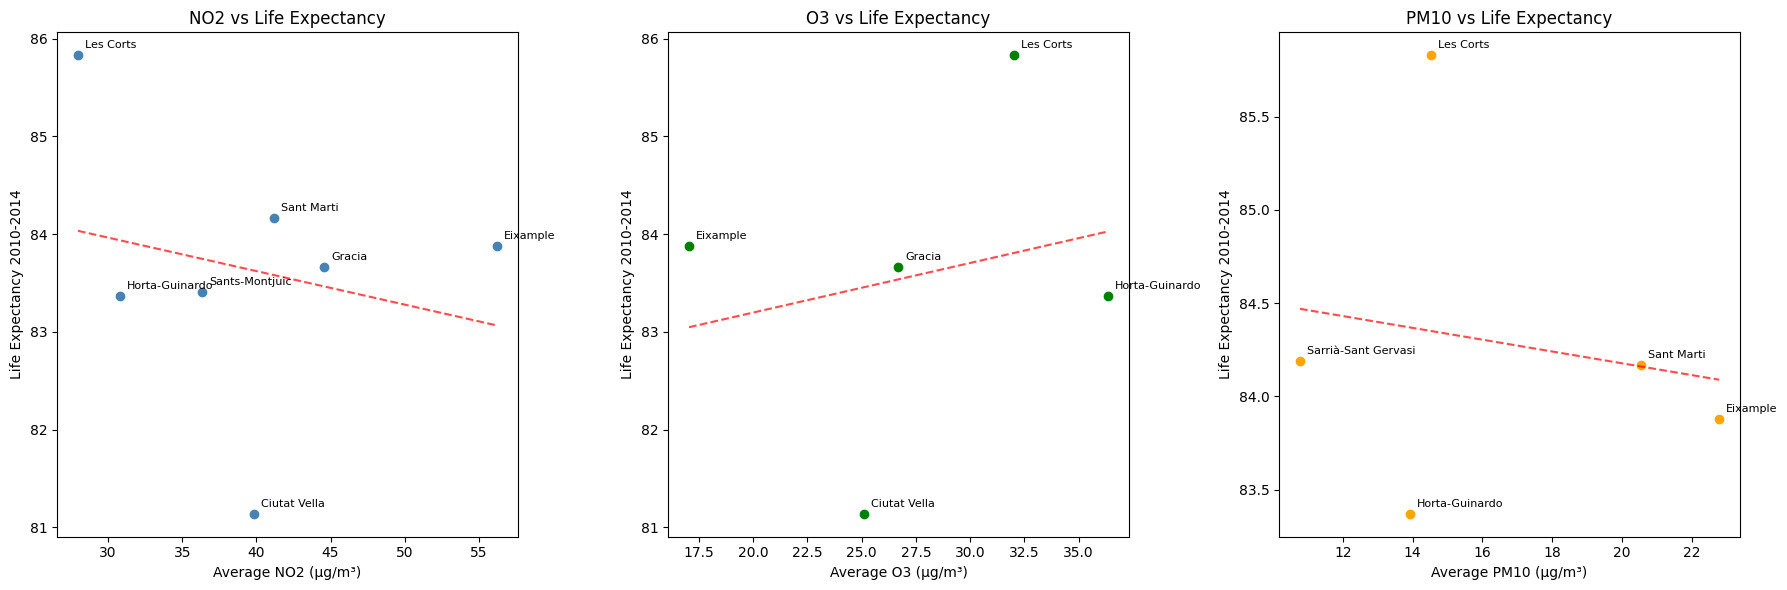

In [15]:
from re import X
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#Data cleaning setiap polutan
df_NO2_clean = df_barcelona_NO2.dropna(subset=['AVG_NO2_Value'])
df_O3_clean = df_barcelona_O3.dropna(subset=['AVG_O3_Value'])
df_PM10_clean = df_barcelona_PM10.dropna(subset=['AVG_PM10_Value'])

#List data
pollutants = [
 (df_NO2_clean, 'AVG_NO2_Value','NO2 vs Life Expectancy', 'steelblue'),
 (df_O3_clean, 'AVG_O3_Value','O3 vs Life Expectancy', 'green'),
 (df_PM10_clean, 'AVG_PM10_Value','PM10 vs Life Expectancy','orange')]

for ax, (df, col, title, color) in zip(axes, pollutants):
    ax.scatter(df[col],df['AVG_2010_2014'], color=color)

    for i, row in df.iterrows():
      ax.annotate(row['District Name'], (row[col], row['AVG_2010_2014']),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

    z = np.polyfit(df[col],df['AVG_2010_2014'],1)
    p = np.poly1d(z)
    x_line = np.linspace(df[col].min(),df[col].max(),100)
    ax.plot(x_line, p(x_line), "r--", alpha=0.7, label='Trend')

    ax.set_title(title)
    ax.set_xlabel(f'Average {col.replace("AVG_","").replace("_Value","")} (µg/m³)')
    ax.set_ylabel('Life Expectancy 2010-2014')

plt.tight_layout()
plt.show()


In [ ]:
from scipy import stats

for df, col, name in [
    (df_NO2_clean, 'AVG_NO2_Value', 'NO2'),
    (df_O3_clean, 'AVG_O3_Value', 'O3'),
    (df_PM10_clean, 'AVG_PM10_Value', 'PM10')
]:
    corr, pvalue = stats.pearsonr(df[col], df['AVG_2010_2014'])
    print(f"{name}: correlation = {corr:.3f}, p-value = {pvalue:.3f}")